# DMS: material taxonomy and model classes

This analysis examines the taxonomy and model-class mapping distributed with Apple's DMS repository, together with measured archive-directory statistics. The source revision is recorded in `datasets/dms/source.json`. Dataset annotations are CC BY-NC 4.0; code and model terms are documented separately.

In [9]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "datasets/dtd/source.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside a cloned Fitwell-AI repository")
plt.rcParams.update({"figure.facecolor": "#f5f1ea", "axes.facecolor": "#f5f1ea", "font.size": 11})
print("Repository:", ROOT.name)


Repository: Fitwell-AI


In [10]:
taxonomy = pd.read_csv(ROOT / "datasets/dms/taxonomy.csv")
model = pd.read_csv(ROOT / "datasets/dms/model_classes.csv")
assert taxonomy.label_id.is_unique
assert len(model) == 46 and model.model_channel.tolist() == list(range(46))
assert set(model.label_id) <= set(taxonomy.label_id)
print("Taxonomy entries:", len(taxonomy))
print("Semantic label IDs:", int(taxonomy.semantic_label.sum()))
print("Pretrained model output classes:", len(model))
print(model.to_string(index=False))

Taxonomy entries: 57
Semantic label IDs: 52
Pretrained model output classes: 46
 model_channel  label_id         material_name       shortname
             0         1           Animal skin            hide
             1         2       Bone/teeth/horn            bone
             2         3             Brickwork           brick
             3         4             Cardboard       cardboard
             4         5            Carpet/rug          carpet
             5         6          Ceiling tile     ceilingtile
             6         7               Ceramic         ceramic
             7         8 Chalkboard/blackboard      chalkboard
             8         9               Clutter         clutter
             9        10              Concrete        concrete
            10        11        Cork/corkboard            cork
            11        12      Engineered stone engineeredstone
            12        13          Fabric/cloth          fabric
            13        15              

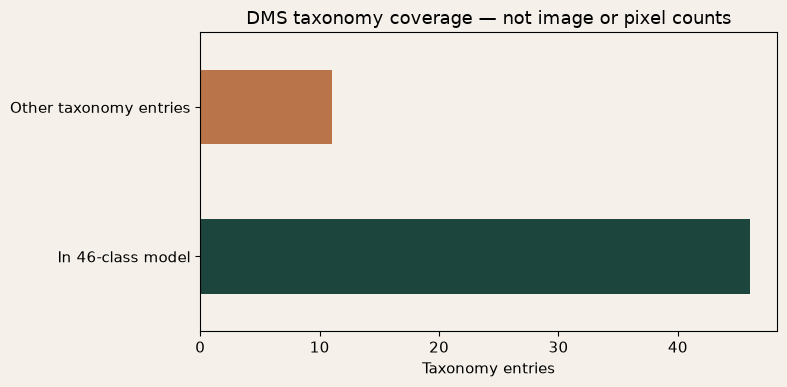

In [11]:
counts = pd.Series({"In 46-class model": int(taxonomy.in_dms46_model.sum()), "Other taxonomy entries": int((~taxonomy.in_dms46_model).sum())})
fig, ax = plt.subplots(figsize=(8, 4))
counts.plot.barh(ax=ax, color=["#1c463d", "#b97449"])
ax.set_xlabel("Taxonomy entries")
ax.set_title("DMS taxonomy coverage — not image or pixel counts")
plt.tight_layout()
plt.show()

        parent_directory  file_count  uncompressed_bytes
                  DMS_v1           3            22728840
      DMS_v1/labels/test       10168           183319653
     DMS_v1/labels/train       24251           449409296
DMS_v1/labels/validation       10138           182496585


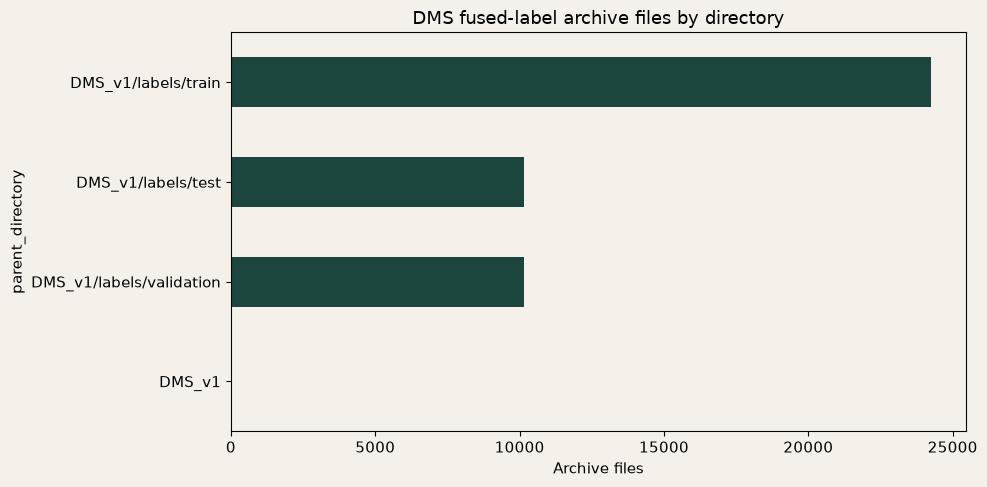

In [12]:
summary_path = ROOT / "datasets/dms/archive_summary.csv"
if summary_path.exists():
    summary = pd.read_csv(summary_path)
    print(summary.to_string(index=False))
    if not summary.empty:
        plot_data = summary.nlargest(12, "file_count").set_index("parent_directory")["file_count"]
        fig, ax = plt.subplots(figsize=(10, 5))
        plot_data.sort_values().plot.barh(ax=ax, color="#1c463d")
        ax.set_xlabel("Archive files")
        ax.set_title("DMS fused-label archive files by directory")
        plt.tight_layout()
        plt.show()
else:
    print("Archive summary not imported yet. No mask-frequency or accuracy graph is fabricated.")

## Interpretation

Dataset label identifiers differ from model output-channel indexes; their correspondence is recorded in `model_classes.csv`. Segmentation training requires matching RGB photographs from Open Images in addition to the label masks. Taxonomy size and archive file counts do not quantify material occurrence or segmentation performance. This notebook contains descriptive analysis rather than model optimisation or evaluation.

In [13]:
# Check the original material table
raw = pd.read_csv(ROOT / "datasets/dms/taxonomy.csv")

print("Rows:", len(raw))
print("Columns:", len(raw.columns))
print("Repeated rows:", raw.duplicated().sum())
print("Repeated material IDs:", raw["label_id"].duplicated().sum())

print("\nMissing values in each column:")
display(raw.isna().sum().to_frame("missing_values"))

display(raw.head(10))

Rows: 57
Columns: 9
Repeated rows: 0
Repeated material IDs: 0

Missing values in each column:


,missing_values
label_id,0
name,0
shortname,0
semantic_label,0
in_dms46_model,0
dms46_channel,11
srgb_red,0
srgb_green,0
srgb_blue,0


,label_id,name,shortname,semantic_label,in_dms46_model,dms46_channel,srgb_red,srgb_green,srgb_blue
0,0,No label,none,False,False,NaN,0,0,0
1,1,Animal skin,hide,True,True,0.0,188,188,137
2,2,Bone/teeth/horn,bone,True,True,1.0,0,188,0
3,3,Brickwork,brick,True,True,2.0,188,188,0
4,4,Cardboard,cardboard,True,True,3.0,0,0,188
5,5,Carpet/rug,carpet,True,True,4.0,188,0,188
6,6,Ceiling tile,ceilingtile,True,True,5.0,0,188,188
7,7,Ceramic,ceramic,True,True,6.0,241,241,241
8,8,Chalkboard/blackboard,chalkboard,True,True,7.0,0,137,137
9,9,Clutter,clutter,True,True,8.0,225,0,0


In [14]:
clean = raw.copy()

# Remove accidental spaces from column names and text
clean.columns = clean.columns.str.strip()

for column in ["name", "shortname"]:
    clean[column] = clean[column].astype("string").str.strip()

# Remove completely identical rows
clean = clean.drop_duplicates().copy()

# Check that material IDs are valid integers
clean["label_id"] = pd.to_numeric(
    clean["label_id"], errors="raise"
).astype("Int64")

# This column may legitimately contain missing values
clean["dms46_channel"] = pd.to_numeric(
    clean["dms46_channel"], errors="raise"
).astype("Int64")

# Stop if important information is missing or ambiguous
assert clean["label_id"].notna().all(), "A material ID is missing."
assert clean["label_id"].is_unique, "Repeated material IDs need review."
assert clean["name"].notna().all(), "A material name is missing."
assert clean["name"].ne("").all(), "A material name is blank."

# Confirm that the separate model mapping agrees with the taxonomy
mapping = pd.read_csv(ROOT / "datasets/dms/model_classes.csv")

assert mapping["model_channel"].tolist() == list(range(46))
assert mapping["label_id"].is_unique

expected = set(
    clean.loc[clean["in_dms46_model"].eq(True), "label_id"]
)
assert set(mapping["label_id"]) == expected

print("Rows before cleaning:", len(raw))
print("Rows after cleaning:", len(clean))
print("Exact duplicate rows removed:", len(raw) - len(clean))

display(clean)

Rows before cleaning: 57
Rows after cleaning: 57
Exact duplicate rows removed: 0


,label_id,name,shortname,semantic_label,in_dms46_model,dms46_channel,srgb_red,srgb_green,srgb_blue
0,0,No label,none,False,False,<NA>,0,0,0
1,1,Animal skin,hide,True,True,0,188,188,137
2,2,Bone/teeth/horn,bone,True,True,1,0,188,0
3,3,Brickwork,brick,True,True,2,188,188,0
4,4,Cardboard,cardboard,True,True,3,0,0,188
5,5,Carpet/rug,carpet,True,True,4,188,0,188
6,6,Ceiling tile,ceilingtile,True,True,5,0,188,188
7,7,Ceramic,ceramic,True,True,6,241,241,241
8,8,Chalkboard/blackboard,chalkboard,True,True,7,0,137,137
9,9,Clutter,clutter,True,True,8,225,0,0


In [15]:
interior_names = [
    "Brickwork",
    "Carpet/rug",
    "Ceiling tile",
    "Ceramic",
    "Concrete",
    "Cork/corkboard",
    "Engineered stone",
    "Fabric/cloth",
    "Glass",
    "Leather",
    "Metal",
    "Mirror",
    "Paint/plaster/enamel",
    "Stone, natural",
    "Stone, polished",
    "Tile",
    "Wallpaper",
    "Wood",
]

interior = clean[
    clean["name"].isin(interior_names)
].copy()

display(interior[["label_id", "name", "dms46_channel"]])

print("Selected interior categories:", len(interior))

,label_id,name,dms46_channel
3,3,Brickwork,2
5,5,Carpet/rug,4
6,6,Ceiling tile,5
7,7,Ceramic,6
10,10,Concrete,9
11,11,Cork/corkboard,10
12,12,Engineered stone,11
13,13,Fabric/cloth,12
20,20,Glass,18
24,24,Leather,21


Selected interior categories: 18


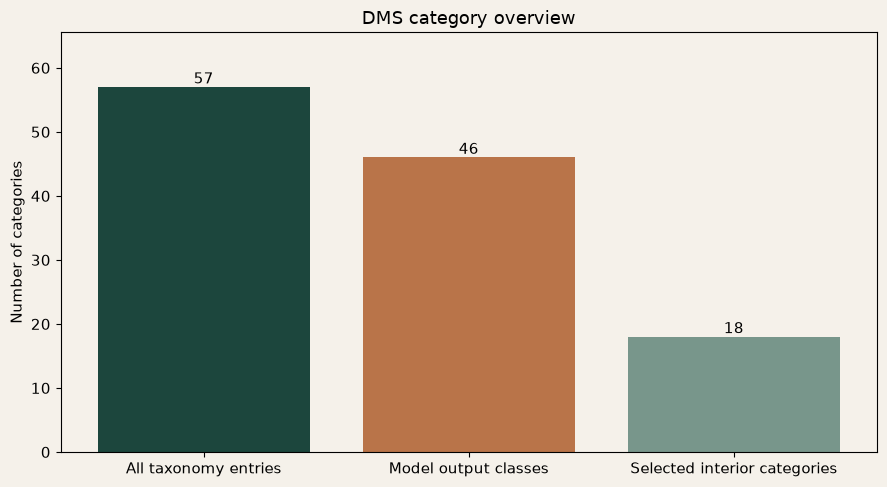

Saved files to: c:\Users\Samiha Abeda Nur\Downloads\Fitwell-AI\datasets\dms\local_data\analysis


In [16]:
output = ROOT / "datasets/dms/local_data/analysis"
output.mkdir(parents=True, exist_ok=True)

clean.to_csv(output / "taxonomy_clean.csv", index=False)
interior.to_csv(output / "interior_materials.csv", index=False)

counts = pd.Series({
    "All taxonomy entries": len(clean),
    "Model output classes": len(mapping),
    "Selected interior categories": len(interior),
})

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    counts.index,
    counts.values,
    color=["#1c463d", "#b97449", "#78968b"]
)

ax.bar_label(bars)
ax.set_ylabel("Number of categories")
ax.set_title("DMS category overview")
ax.set_ylim(0, counts.max() * 1.15)

fig.tight_layout()
fig.savefig(
    output / "dms_category_overview.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
print("Saved files to:", output)

In [20]:
from pathlib import Path
import pandas as pd

root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "datasets/dms").is_dir()
)

manifest = pd.read_csv(
    root / "datasets/dms/local_data/DMS_v1/pilot_manifest.csv"
)

# Count accepted and excluded records
display(pd.crosstab(manifest["split"], manifest["status"]))

# Show the most frequent explanations
display(
    manifest.groupby(["status", "detail"], dropna=False)
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
    .head(15)
)

status,accepted,excluded
split,,
test,0,25
train,13,187
validation,3,47


,status,detail,count
2,excluded,HTTP Error 429: Too Many Requests,258
0,accepted,NaN,16
1,excluded,HTTP 429: server rate limit; Retry-After: not ...,1


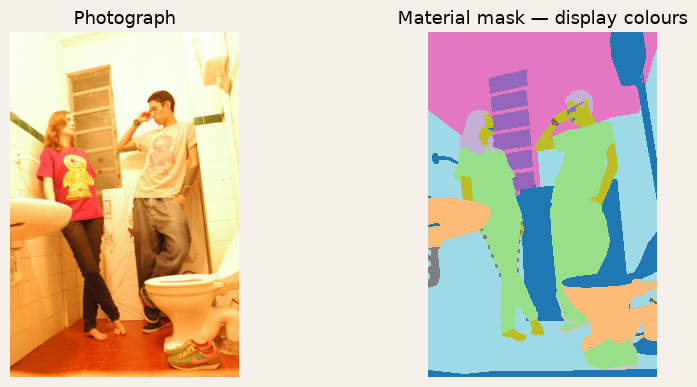

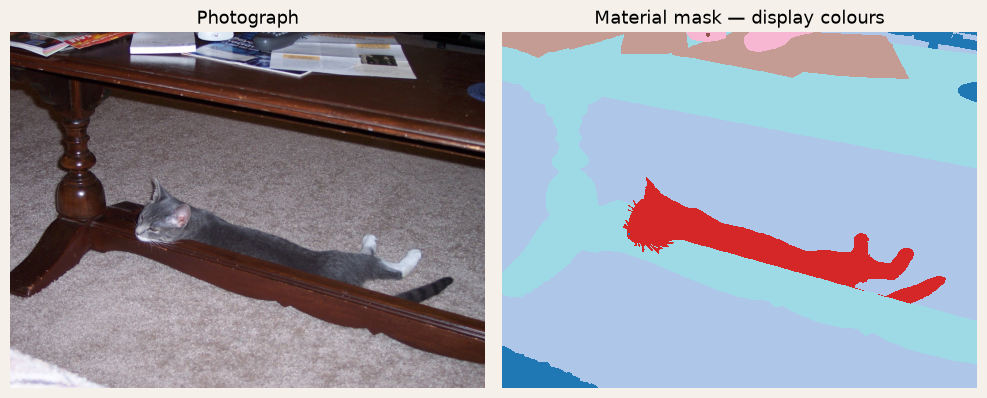

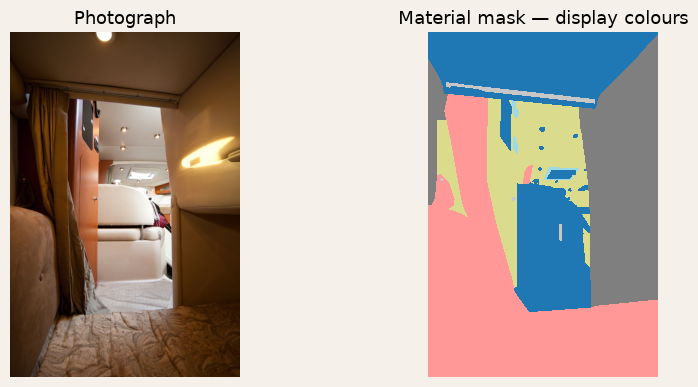

In [21]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "datasets/dms").is_dir()
)
data = root / "datasets/dms/local_data/DMS_v1"
manifest = pd.read_csv(data / "pilot_manifest.csv")

accepted = manifest[
    (manifest["status"] == "accepted") &
    (manifest["split"] == "train")
].head(3)

for _, row in accepted.iterrows():
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    with Image.open(data / row["image_path"]) as image:
        axes[0].imshow(image)

    with Image.open(data / row["label_path"]) as mask:
        axes[1].imshow(mask, cmap="tab20", interpolation="nearest")

    axes[0].set_title("Photograph")
    axes[1].set_title("Material mask — display colours")
    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

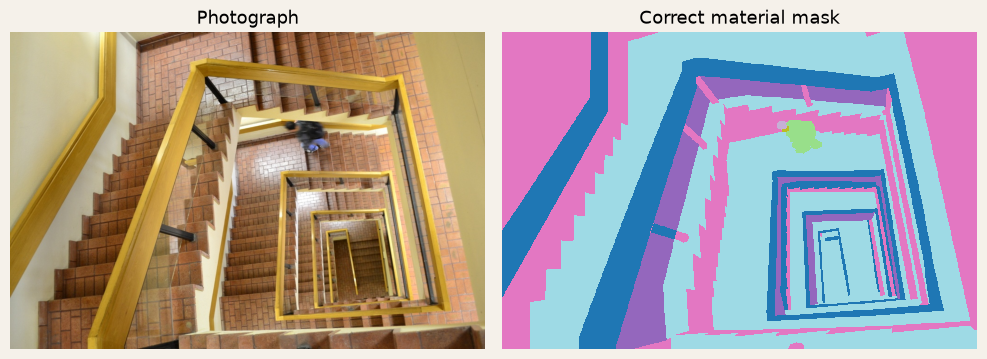

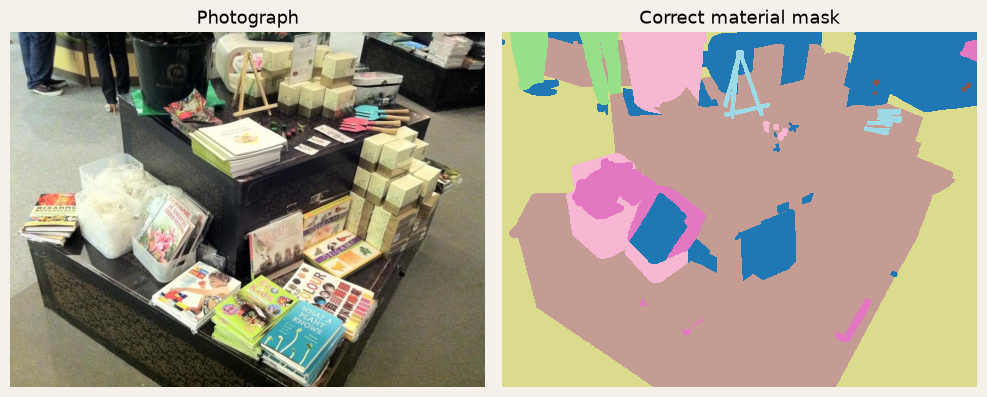

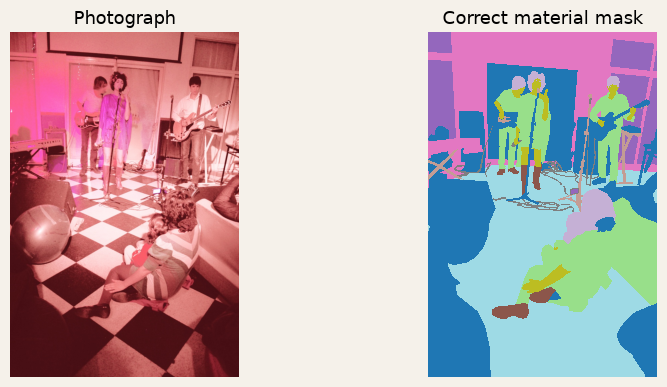

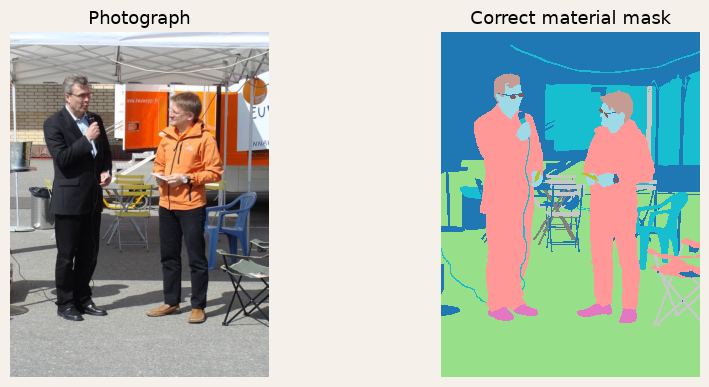

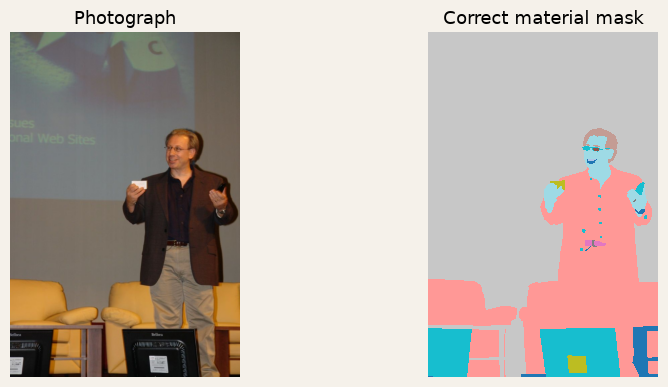

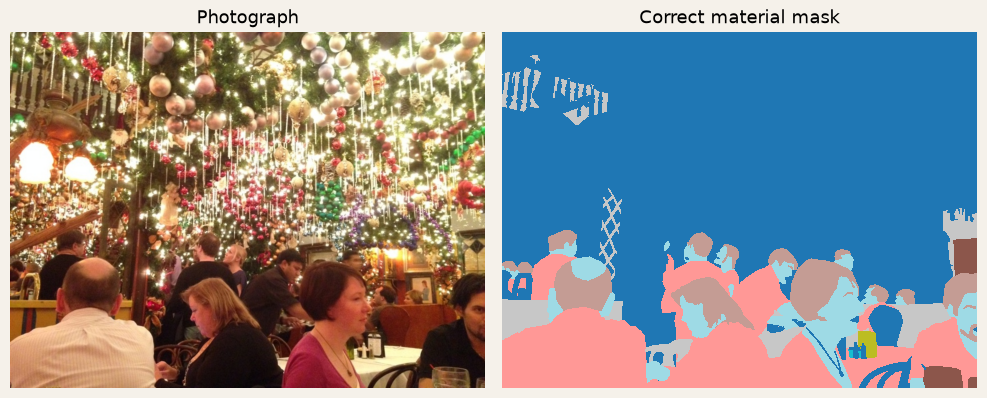

In [22]:
from PIL import Image
import matplotlib.pyplot as plt

data = root / "datasets/dms/local_data/DMS_v1"
manifest = pd.read_csv(data / "pilot_manifest.csv")

accepted = manifest[
    (manifest["status"] == "accepted") &
    (manifest["split"] == "train")
].sample(6, random_state=42)

for _, row in accepted.iterrows():
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    with Image.open(data / row["image_path"]) as photo:
        axes[0].imshow(photo)

    with Image.open(data / row["label_path"]) as mask:
        axes[1].imshow(mask, cmap="tab20", interpolation="nearest")

    axes[0].set_title("Photograph")
    axes[1].set_title("Correct material mask")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()